<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB
None
   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40


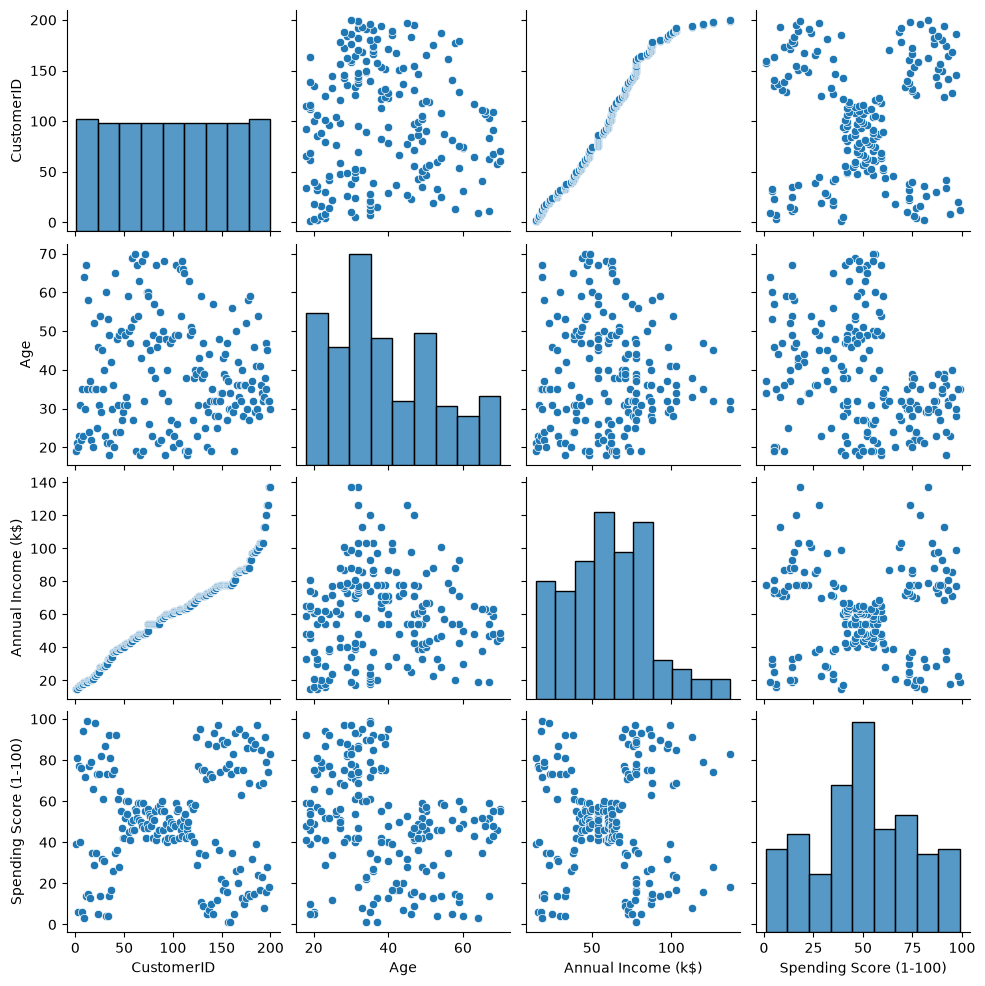

KMeans(n_clusters=5, n_init=10, random_state=42)
   Annual Income (k$)  Spending Score (1-100)  label
0                  15                      39      4
1                  15                      81      2
2                  16                       6      4
3                  16                      77      2
4                  17                      40      4


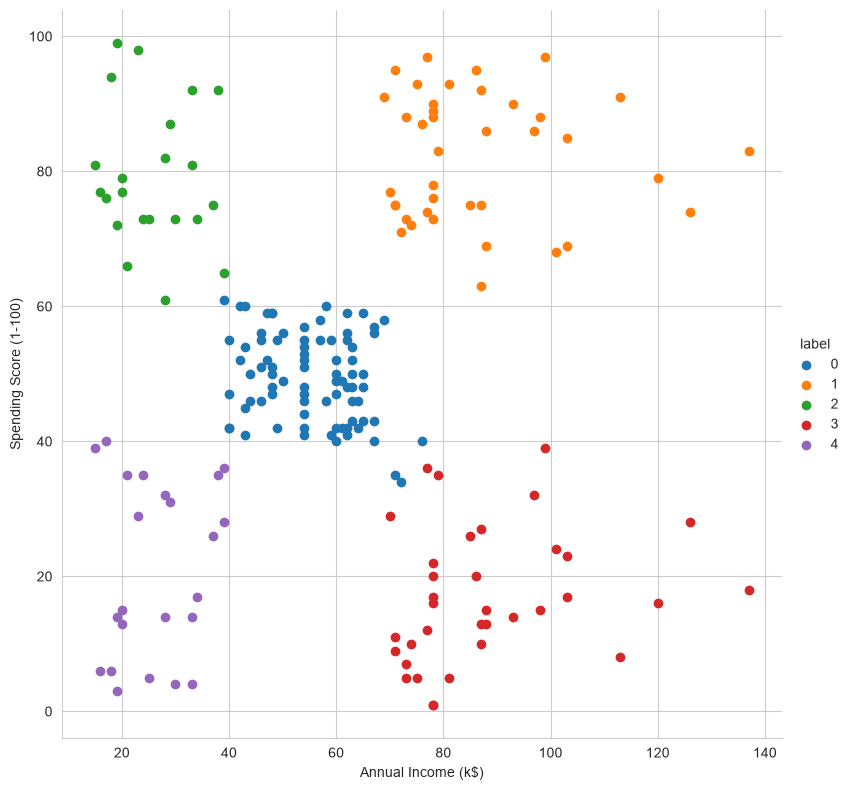

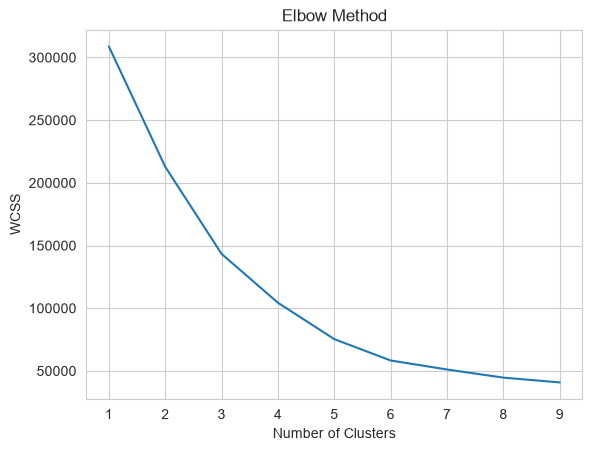

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans

# Read dataset from CSV file
df = pd.read_csv("Mall_Customers.csv")

print(df.info())
print(df.head())

# Visualize relationships between columns
sns.pairplot(df)
plt.show()

# Select Annual Income and Spending Score for clustering
features = df[["Annual Income (k$)", "Spending Score (1-100)"]].values

# Apply K-Means clustering
model = KMeans(n_clusters=5, random_state=42, n_init=10)
model.fit(features)

print(model)

# Add cluster labels to the selected data
final = df[["Annual Income (k$)", "Spending Score (1-100)"]].copy()
final["label"] = model.predict(features)

print(final.head())

# Display the clusters
sns.set_style("whitegrid")
sns.FacetGrid(final, hue="label", height=8).map(
    plt.scatter,
    "Annual Income (k$)",
    "Spending Score (1-100)"
).add_legend()

plt.show()

# Elbow method to find the suitable number of clusters
features_el = df[["Age", "Annual Income (k$)", "Spending Score (1-100)"]].values

wcss = []

for i in range(1, 10):
    model = KMeans(n_clusters=i, random_state=42, n_init=10)
    model.fit(features_el)
    wcss.append(model.inertia_)

plt.plot(range(1, 10), wcss)
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.show()